In [1]:
from config import Config
from DataManager import DataManager
from DataPreprocessor import Preprocessor
from FeatureSelection import FeatureSelector
from ModelManager import ModelManager
from ModelEvaluation import Evaluator

from DataExplorer import Explorer #new


from sklearn.model_selection import train_test_split

import pandas as pd
import numpy as np

In [4]:
%load_ext autoreload
%autoreload 2

In [5]:
cfg = Config()
data_manager = DataManager(cfg)
preprocessor = Preprocessor(cfg)

gt_df = data_manager.load_ground_truth()
wl = data_manager.load_wavelengths()

#image = data_manager.load_image(1200)
#processed = preprocessor.process_image(image)

X, y, valid_indices = preprocessor.process_dataset(data_manager, gt_df)
X.shape


(1732, 150)

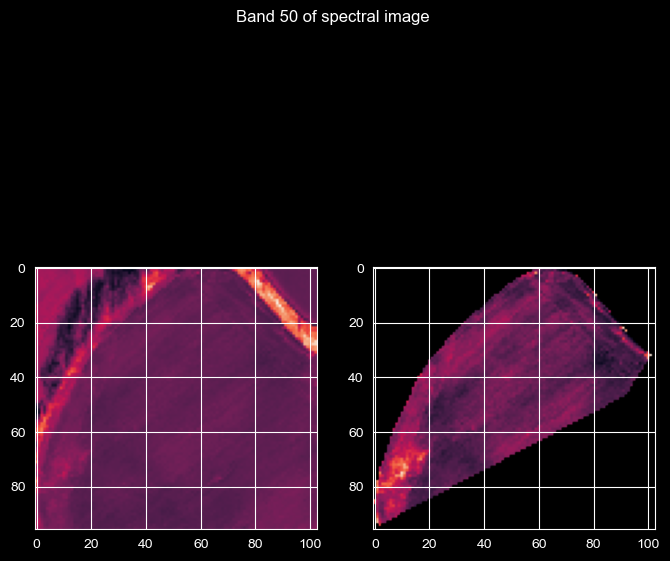

In [12]:
image_data = data_manager.load_image(1700)#1700 image - takie samo jak wcześniej
Explorer.compare_masked_vs_not_masked(image_data, 50 )


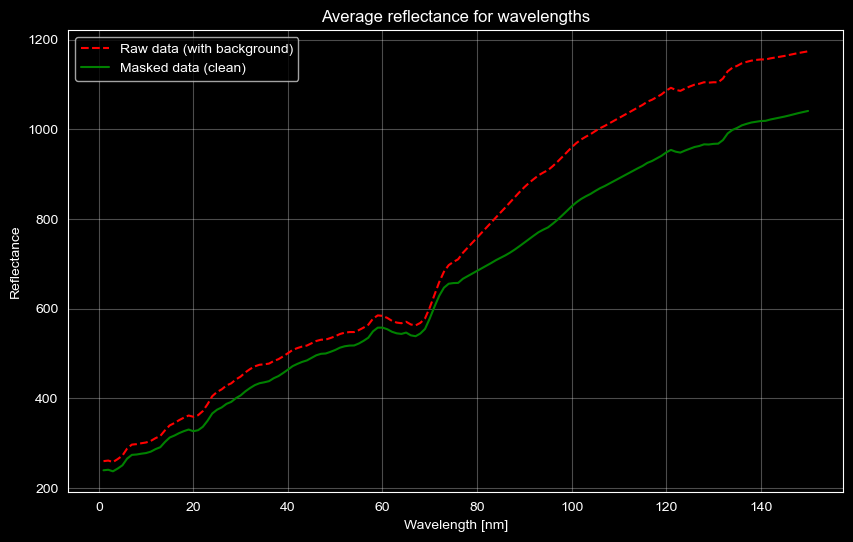

In [13]:
Explorer.plot_single_image_spectrum(image_data, wl)

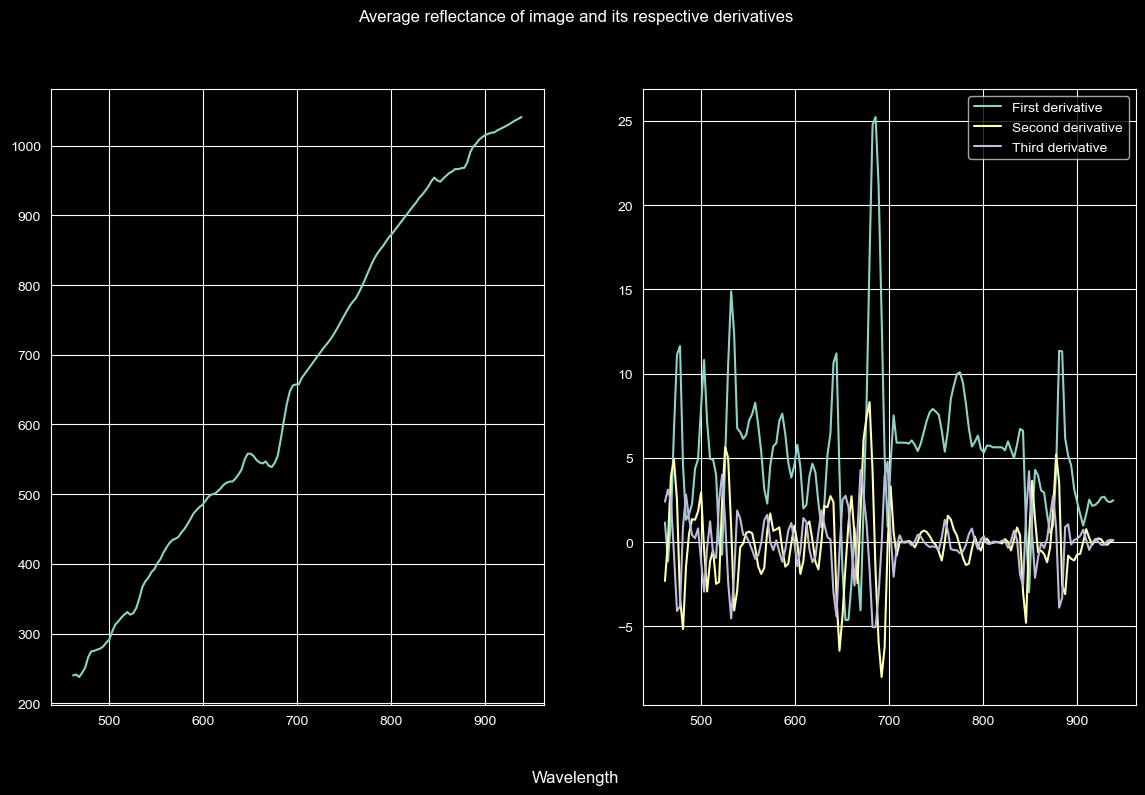

In [16]:
#Calculating and plotting first, second and third order derivatives of avg spectral reflectance curve
Explorer.plot_image_derivatives(image_data, wl)

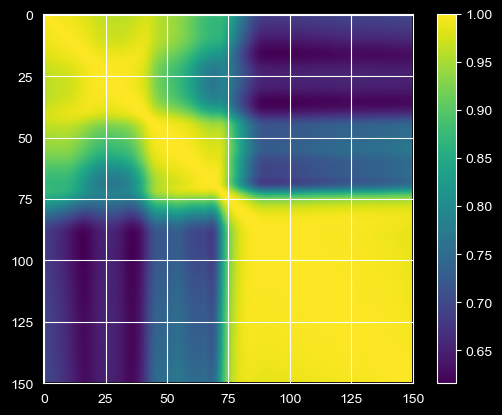

In [17]:
#Calculating correlation between bands of the example image
Explorer.plot_band_correlation_matrix(image_data)

In [18]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=cfg.RANDOM_SEED)

In [28]:
selector = FeatureSelector(cfg, n_features=25) #tu zmieniłem z 15 na 25 bo był jakiś błąd
selector.fit(X_train, y_train)

X_train_rfe = selector.transform(X_train)
X_test_rfe = selector.transform(X_test)

Fitting estimator with 150 features.
Fitting estimator with 145 features.
Fitting estimator with 140 features.
Fitting estimator with 135 features.
Fitting estimator with 130 features.
Fitting estimator with 125 features.
Fitting estimator with 120 features.
Fitting estimator with 115 features.
Fitting estimator with 110 features.
Fitting estimator with 105 features.
Fitting estimator with 100 features.
Fitting estimator with 95 features.
Fitting estimator with 90 features.
Fitting estimator with 85 features.
Fitting estimator with 80 features.
Fitting estimator with 75 features.
Fitting estimator with 70 features.
Fitting estimator with 65 features.
Fitting estimator with 60 features.
Fitting estimator with 55 features.
Fitting estimator with 50 features.
Fitting estimator with 45 features.
Fitting estimator with 40 features.
Fitting estimator with 35 features.
Fitting estimator with 30 features.


In [29]:
models = ModelManager(cfg)

models.tune_fit(X_train_rfe, y_train, verbose=True)
y_pred = models.predict(X_test_rfe)


Fitting 5 folds for each of 20 candidates, totalling 100 fits
Best params for [P] parameter: {'n_estimators': 1000, 'min_samples_split': 2, 'min_samples_leaf': 4, 'max_features': 'log2', 'max_depth': 30}

Fitting 5 folds for each of 20 candidates, totalling 100 fits
Best params for [K] parameter: {'n_estimators': 300, 'min_samples_split': 5, 'min_samples_leaf': 4, 'max_features': None, 'max_depth': 40}

Fitting 5 folds for each of 20 candidates, totalling 100 fits
Best params for [Mg] parameter: {'n_estimators': 1000, 'min_samples_split': 5, 'min_samples_leaf': 4, 'max_features': 'sqrt', 'max_depth': 20}

Fitting 5 folds for each of 20 candidates, totalling 100 fits
Best params for [pH] parameter: {'n_estimators': 1000, 'min_samples_split': 5, 'min_samples_leaf': 1, 'max_features': 'sqrt', 'max_depth': 50}



In [30]:
evaluator = Evaluator(cfg)
y_baseline = ModelManager.get_baseline_predictions(X_train=X_train_rfe, y_train=y_train,X_test=X_test_rfe)
evaluator.calculate_hyperview_score(y_test, y_pred, y_baseline)

P              0.970280
K              0.945541
Mg             0.914177
pH             0.848254
FINAL_SCORE    0.919563
dtype: float64

In [7]:
models_new = ModelManager(cfg)
models_new.load_models('best_rf_model.pkl')

y_pred_new = models_new.predict(X_test_rfe)
evaluator.calculate_hyperview_score(y_test, y_pred_new, y_baseline)

C:\Users\kam05\anaconda3\Lib\site-packages\sklearn\base.py:463: InconsistentVersionWarning: Trying to unpickle estimator DecisionTreeRegressor from version 1.6.1 when using version 1.8.0. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
C:\Users\kam05\anaconda3\Lib\site-packages\sklearn\base.py:463: InconsistentVersionWarning: Trying to unpickle estimator RandomForestRegressor from version 1.6.1 when using version 1.8.0. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(


NameError: name 'X_test_rfe' is not defined

In [6]:
#test wyboru pliku potem do wyrzucenua

from Users import Farmer
cfg = Config()
farmer = Farmer(cfg, user_id=1) #

print("odpalamy okno")

# metoda ktora pozwala w konie windowsa wybrac obraz
farmer.load_data_from_desktop()

if farmer.data is not None:
    print("\nWczytano obraz.")
    print(f"Wymiary danych: {farmer.data.shape}")
else:
    print("\nAnulowano wybór lub wystąpił błąd.")


odpalamy okno

Anulowano wybór lub wystąpił błąd.
